# 00: Reproduce the baseline

**Goal of this notebook:** run Luke's notebook #4 experiment through our own `trustqem` modules and check that we get
*exactly* his numbers. If we do, our code is a faithful copy and everything we build on top of it is fair.

Read the short explainers as you go. They're the words you'll need at the poster.

## Words you need first

**Qubit.** A bit is 0 or 1. A qubit can be in a blend of 0 and 1 until you look at it. Looking (measuring) forces it to
pick, randomly, with probabilities set by the blend. *Coin analogy: a coin spinning on a table is "both" until you slap
your hand on it.*

**Gate.** An operation that changes qubits. `rx`, `ry`, `rz` rotate one qubit by an angle (they change the blend).
`cx` (controlled-X) flips the second qubit only if the first is 1. That's what creates *entanglement*: the qubits'
results become linked.

**Circuit.** A recipe of gates, read left to right. In this project: random rotations on 4 qubits, then some `cx`
gates, repeated 1 to 12 times (each repeat is a *layer*).

**Shot.** One run of the circuit ending in a measurement. One shot gives one string like `0110`. You need many shots
(here 1000) to estimate probabilities, just like flipping a coin 1000 times to estimate if it's fair.

**Observable and expectation value.** A question you ask the measured bits, scored +1 or -1 per shot. `Z` on qubit 0
asks "was qubit 0 a 0 (+1) or a 1 (-1)?". `ZZ` on two qubits asks "did they agree (+1) or disagree (-1)?". The
*expectation value* is the average score over all shots, a number between -1 and +1. **This number is what every
method in this project tries to get right.**

In [1]:
# Colab only: uncomment and run. On the Mac, `uv sync` already installed everything.
# !pip install -q "qiskit>=2.0" "qiskit-aer>=0.17" "scikit-learn>=1.5" matplotlib

In [2]:
import logging
import pickle
from pathlib import Path

import numpy as np
from qiskit.quantum_info import SparsePauliOp

from trustqem.circuits import build_random_circuit
from trustqem.config import ExperimentConfig
from trustqem.dataset import generate_dataset
from trustqem.mitigation import (build_model_inputs, learned_predictions, rows_of, split_circuits,
                                 train_learned_mitigator, zne_all_rows)
from trustqem.noise import build_noisy_simulators
from trustqem.plots import plot_error_versus_depth
from trustqem.simulate import (build_observable_labels, build_sign_table, exact_noisy_expectation_values,
                               ideal_expectation_values, sampled_expectation_values)

logging.basicConfig(level=logging.WARNING, format="%(message)s")
logging.getLogger("trustqem").setLevel(logging.INFO)   # our progress messages only, not qiskit internals
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

config = ExperimentConfig()          # Luke's defaults
random_generator = np.random.default_rng(config.random_seed)
observable_labels = build_observable_labels(config.qubit_count)
observables = [SparsePauliOp(label) for label in observable_labels]
sign_table = build_sign_table(observable_labels, config.qubit_count)
print(len(observables), "observables:", observable_labels)

7 observables: ['IIIZ', 'IIZI', 'IZII', 'ZIII', 'IIZZ', 'IZZI', 'ZZII']


## Noise

Real quantum gates are imperfect. The simulator models this as **depolarizing noise**: after every gate, with a small
probability (0.3% for one-qubit gates, 3% for `cx`), the qubits are scrambled into pure randomness.

*Analogy: a game of telephone where, now and then, someone mumbles and the next person just guesses.*

Scrambling pulls expectation values toward 0, so an ideal value of 0.80 might come out as 0.62.

In [3]:
simulators = build_noisy_simulators(config)
for scale, simulator in simulators.items():
    print(f"noise scale {scale}: one-qubit rate {scale * config.one_qubit_depolarizing_rate:.4f}, "
          f"cx rate {scale * config.two_qubit_depolarizing_rate:.4f}")

noise scale 1.0: one-qubit rate 0.0030, cx rate 0.0300
noise scale 2.0: one-qubit rate 0.0060, cx rate 0.0600
noise scale 3.0: one-qubit rate 0.0090, cx rate 0.0900


## Look at one circuit

Same example Luke shows (and it uses the random generator in the same order, which keeps our numbers identical to his).
Compare the three rows: **ideal** is the truth, **exact noisy** is what infinite shots on the noisy machine would give,
**sampled noisy** is what 1000 real shots give (noise *plus* shot randomness).

In [4]:
example_circuit, _ = build_random_circuit(3, config.qubit_count, config.cx_probability_per_pair, random_generator)
print(example_circuit.draw(fold=120))
print("ideal:               ", np.round(ideal_expectation_values(example_circuit, observables), 4))
print("exact noisy, 1x:     ", np.round(exact_noisy_expectation_values(example_circuit, simulators[1.0], observables), 4))
print("sampled noisy, 1x:   ", np.round(sampled_expectation_values(example_circuit, simulators[1.0],
                                         config.shots_per_circuit, sign_table, random_generator), 4))
print("exact noisy, 3x:     ", np.round(exact_noisy_expectation_values(example_circuit, simulators[3.0], observables), 4))

      ┌────────────┐┌────────────┐              ┌────────────┐                        
q_0: ─┤ Rx(2.7576) ├┤ Rz(2.3298) ├──────■───────┤ Rz(3.9689) ├────────────────────────
      ├────────────┤├───────────┬┘    ┌─┴─┐     ├────────────┤                        
q_1: ─┤ Rz(5.3947) ├┤ Ry(5.823) ├─────┤ X ├─────┤ Rz(4.7632) ├────────────────■───────
     ┌┴────────────┤└───────────┘ ┌───┴───┴────┐└────────────┘┌────────────┐┌─┴─┐     
q_2: ┤ Rx(0.59173) ├──────■───────┤ Rz(5.1696) ├──────■───────┤ Rz(6.0991) ├┤ X ├──■──
     └─┬──────────┬┘    ┌─┴─┐     ├────────────┤    ┌─┴─┐     ├────────────┤└───┘┌─┴─┐
q_3: ──┤ Rz(6.13) ├─────┤ X ├─────┤ Ry(2.7861) ├────┤ X ├─────┤ Ry(5.6116) ├─────┤ X ├
       └──────────┘     └───┘     └────────────┘    └───┘     └────────────┘     └───┘
ideal:                [-0.9272 -0.8307 -0.6895  0.3261  0.896   0.83   -0.5541]
exact noisy, 1x:      [-0.8913 -0.77   -0.578   0.2717  0.833   0.7282 -0.4997]
sampled noisy, 1x:    [-0.904 -0.784 -0.59   0.284  0.844

## Build the dataset (about a minute)

400 random circuits × 7 observables = 2800 rows. For each: the ideal value, sampled values at noise 1×, 2×, 3×, and
reference values.

In [5]:
dataset = generate_dataset(config, simulators, observables, observable_labels, sign_table, random_generator)
print("rows:", len(dataset.row_ideal_values))

simulated 50/400 circuits in 7s


simulated 100/400 circuits in 14s


simulated 150/400 circuits in 21s


simulated 200/400 circuits in 29s


simulated 250/400 circuits in 36s


simulated 300/400 circuits in 43s


simulated 350/400 circuits in 51s


simulated 400/400 circuits in 58s


rows: 2800


## Two ways to undo the noise

**ZNE (zero-noise extrapolation).** Run the circuit at 1×, 2×, 3× noise, draw a line (or curve) through the three
results, and read off where it would be at 0× noise. *Analogy: time a runner with a 10 kg, 20 kg, 30 kg backpack
and extrapolate to no backpack.*
Catch: the line multiplies the shot randomness, so linear ZNE is about 1.5× noisier and quadratic about 4.4× noisier.

**Learned mitigation.** Train a model (gradient boosting) on 300 circuits where we *know* the ideal answer: input =
the three noisy values + circuit facts (depth, number of `cx`), output = the ideal value. Then use it on new circuits.
Catch: on real hardware you can't get ideal answers for most circuits. That's exactly where our Clifford trick will
come in later.

In [6]:
scales = config.noise_scale_factors
train_circuits, test_circuits = split_circuits(config.number_of_circuits, config.test_fraction, config.random_seed)
train_rows, test_rows = rows_of(dataset, train_circuits), rows_of(dataset, test_circuits)

model_inputs = build_model_inputs(dataset)
model = train_learned_mitigator(model_inputs[train_rows], dataset.row_ideal_values[train_rows], config)

method_predictions = {
    "unmitigated": dataset.row_noisy_values[:, 0],
    "unmitigated, 3x shots": dataset.row_matched_budget_values,
    "ZNE linear": zne_all_rows(dataset.row_noisy_values, scales, 1),
    "ZNE quadratic": zne_all_rows(dataset.row_noisy_values, scales, 2),
    "learned": learned_predictions(model, model_inputs),
    "ZNE linear, exact values": zne_all_rows(dataset.row_exact_noisy_values, scales, 1),
    "ZNE quadratic, exact values": zne_all_rows(dataset.row_exact_noisy_values, scales, 2),
}
test_errors = {name: np.abs(pred[test_rows] - dataset.row_ideal_values[test_rows])
               for name, pred in method_predictions.items()}
print(f"{'method':30s}{'mean abs error':>16s}")
for name, errors in test_errors.items():
    print(f"{name:30s}{errors.mean():16.4f}")

method                          mean abs error
unmitigated                             0.0526
unmitigated, 3x shots                   0.0502
ZNE linear                              0.0426
ZNE quadratic                           0.0991
learned                                 0.0339
ZNE linear, exact values                0.0157
ZNE quadratic, exact values             0.0033


## The reproduction check

These are the numbers Luke's own notebook printed when run unmodified on this Mac (Oct 24). If every line matches,
our modules are a faithful copy.

In [7]:
LUKE_REFERENCE_TEST_MAE = {
    "unmitigated": 0.0526, "unmitigated, 3x shots": 0.0502, "ZNE linear": 0.0426, "ZNE quadratic": 0.0991,
    "learned": 0.0339, "ZNE linear, exact values": 0.0157, "ZNE quadratic, exact values": 0.0033,
}
for name, expected in LUKE_REFERENCE_TEST_MAE.items():
    ours = round(test_errors[name].mean(), 4)
    assert ours == expected, f"{name}: ours {ours} vs Luke {expected}"
print("All 7 numbers match Luke's notebook exactly.")

All 7 numbers match Luke's notebook exactly.


saved results/00_baseline.pkl and the figure


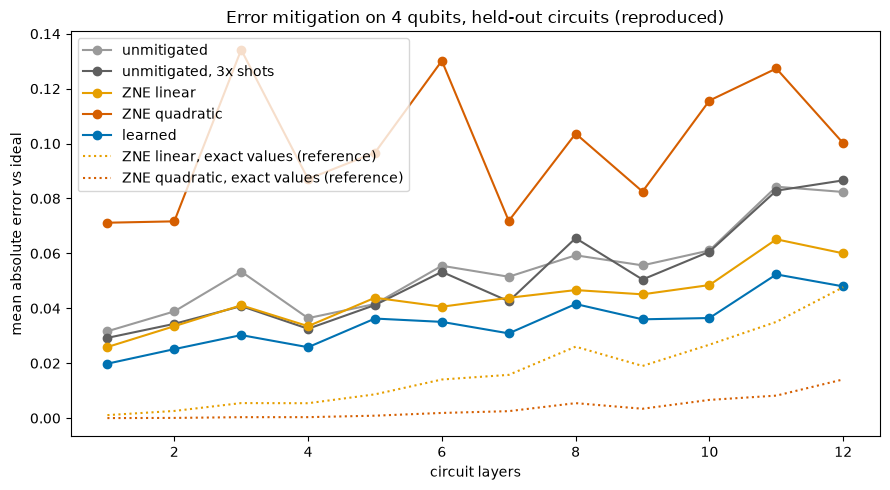

In [8]:
figure = plot_error_versus_depth(test_errors, dataset.row_layer_counts[test_rows],
                                 "Error mitigation on 4 qubits, held-out circuits (reproduced)")
figure.savefig(RESULTS_DIR / "00_baseline_error_vs_depth.png", dpi=200)
with open(RESULTS_DIR / "00_baseline.pkl", "wb") as output_file:
    pickle.dump({"config": config.to_dict(), "dataset": dataset, "train_circuits": train_circuits,
                 "test_circuits": test_circuits, "method_predictions": method_predictions}, output_file)
print("saved results/00_baseline.pkl and the figure")

## Your turn (teach-back)

Answer these in `LEARNING_LOG.md`, in your own words. No looking back at the text above for the first try.

1. What goes *into* the learned model, and what comes *out*?
2. Why does quadratic ZNE do *worse* than doing nothing (0.099 vs 0.053), even though with infinite shots it's the
   best method of all (0.003)?
3. The learned model wins (0.034). What did it need that ZNE didn't, and why is that a problem on a real quantum
   computer?
4. Look at the figure: which method gets worse fastest as circuits get deeper, and why might that be?

Then tell me your answers in chat and I'll play judge.